In [1]:
import numpy as np      

<h1>2.12</h1>

In [2]:
def Bisection(f, a, b, tol=1e-5):
    """Bisection root finder; raises if [a, b] does not bracket a root."""
    
    if tol is None:
        tol = 1e-5 
    
    if f(a) == 0:
        return a
    if f(b) == 0:
        return b
    if np.sign(f(a)) == np.sign(f(b)):  # both endpoints on the same side
        raise ValueError("a and b do not bracket a root")
    
    # initialization of the midpoint
    m = (a+b)/2
    
    # start the loop
    while (b - a) > tol:
        if np.abs(f(m)) < tol: # stopping condition
            return m
        elif np.sign(f(a)) == np.sign(f(m)):
            a = m # squeeze the interval to the right
        elif np.sign(f(m)) == np.sign(f(b)):
            b = m # squeeze the interval to the left
        elif f(a) == 0:
            return a
        elif f(b) == 0:
            return b
            
            
        m = (a+b)/2 # recalculate the midpoint
    
    return m


f =  lambda x: 1 + x
a = -2
b = 3
tol = 0.00001

root = Bisection(f, a, b, tol)
root

-0.9999961853027344

In [3]:
f_0 = lambda x: np.sin(4*x)*np.exp(0.5*x) + 0.3*np.sqrt(x) + 0.1

root_1 = Bisection(f_0, 0.5, 1.25,tol)
root_2 = Bisection(f_0, 1.25, 2,tol)
root_3 = Bisection(f_0, 2, 3, tol)

print(root_1)
print(root_2)
print(root_3)

0.8475971221923828
1.515345573425293
2.398944854736328


<h1>2.13</h1>

In [4]:
f = lambda x: x**2 - 2
a = 0
b = 2 

root_1 = Bisection(f, a, b, tol)
root_1

1.414215087890625

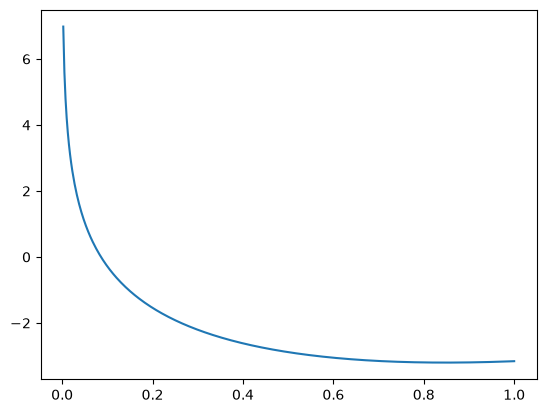

2.495316505432128


In [5]:
import matplotlib.pyplot as plt  

x = np.linspace(0, 1, 400) 

def f(x):
    return np.sin(x) + x**2 - 2*np.log(x) - 5

plt.plot(x, f(x))
plt.show()


f_2 = lambda x: np.sin(x) + x**2 - 2*np.log(x) - 5

root_2 = Bisection(f_2, 0.1, 5, 1e-5)
print(root_2)

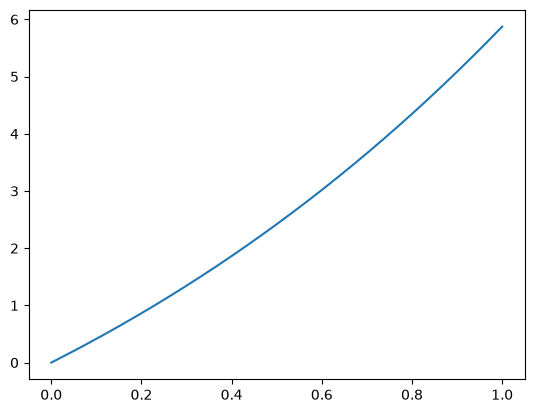

0

In [6]:
f_3 = lambda x: (5-x)*np.exp(x) - 5
a = 0
b = 5 

plt.plot(x, f_3(x))
plt.show()

root_3 = Bisection(f_3, a, b, 1e-5)
root_3

<h1>2.17</h1>

Is the root is exactly at the midpoint, the error is definitely 0. While, if the root is not at the minimum or maximum of the interval (a or b), the error is pretty large with wastes time for calculating.<br>
Thus, if the continuous function in an interval [a, b] has a root, the maximum error is its midpoint m = (a+b)/2 as the approximation of the root is $\frac{|b - a|}{2}$

iteration 1: approximation Error = $\frac{|b-a|}{2^2}$<br>
iteration 2: approximation error = $\frac{|b-a|}{2^3}$<br>
iteration n: approximation error = $\frac{|b-a|}{2^{n+1}}$<br>

Set $\epsilon = \frac{|b-a|}{2^{n+1}}$<br>
Then, $2^{n+1} = \frac{|b-a|}{\epsilon}$<br>
Thus, $n+1 = log_2 \left(\frac{|b-a|}{\epsilon}\right)$<br>
Therefore, $n = log_2 \left(\frac{|b-a|}{\epsilon} \right) - 1$, which is the minimum number of iterations to ensure that the approximation error is less than the tolerance.

In [7]:
def Bisection(f , a , b , tol):
    # The input parameters are
    # f is a Python function or a lambda function
    # a is the lower guess
    # b is the upper guess
    # tol is an optional tolerance for the accuracy of the root
    
    # if the user doesn't define a tolerance we need 
    # code to create a default
    # see default value in function definition
    
    # check that there is a root between a and b
    # if not we should return an error and break the code
    
    if tol is None:
        tol = 1e-5 
        
    if f(a)*f(b) > 0:
        raise Exception("The provided endpoints have the same sign. We cannot guarantee a root is present between them.")

   
    width = b - a
    
    # how many iterations needed?
    numIter = int(-np.log2(tol/width))+1

    # start a while loop
    for i in range(numIter):
        
        # next calculate the midpoint m = (a+b)/2
        m = (a + b)/2
        
        if f(a) * f(m) < 0:
            b = m
            
        elif f(b) * f(m) < 0:
            a = m
        
        elif f(m) ==0:
            a = m
            b = m

    # end the for loop
    
    root = (a + b) / 2
    
    return root

In [8]:
f_0 = lambda x: np.sin(4*x)*np.exp(0.5*x) + 0.3*np.sqrt(x) + 0.1

root_1 = Bisection(f_0, 0.5, 1.25,1e-4)
root_2 = Bisection(f_0, 1.25, 2,1e-4)
root_3 = Bisection(f_0, 2, 3, 1e-4)

print(root_1)
print(root_2)
print(root_3)

0.8475799560546875
1.5153656005859375
2.398956298828125


In [9]:
f_3 = lambda x: (5-x)*np.exp(x) - 5
a = 0
b = 5 

root_3 = Bisection(f_3, a, b, 1e-4)
root_3

4.965095520019531